In [113]:
import networkx as nx
import matplotlib.pyplot as plt


# Criar Grafo com os caminhos do 'jogo' do slide 31 da primeira aula

#### Dica criem os vértices primeiro, depois as arestas (haverão vertíces 'soltos')

#### Lembrando das regras do jogo:

1. Escolher um círculo **qualquer**
2. Ir para o quadrado **mais próximo**
3. Ir para o triângulo **mais próximo**, **apenas** à direita ou abaixo do quadrado
4. Ir para o quadrado mais próximo, **apenas diagonais**
5. Terminar no mesmo lugar que os colegas

Como convenção, vamos combinar que as colunas são nomeadas de A a F; e as linhas de 1 a 6; de modo que o penúltimo elemento da última linha (um quadrado) seja nomeado E6


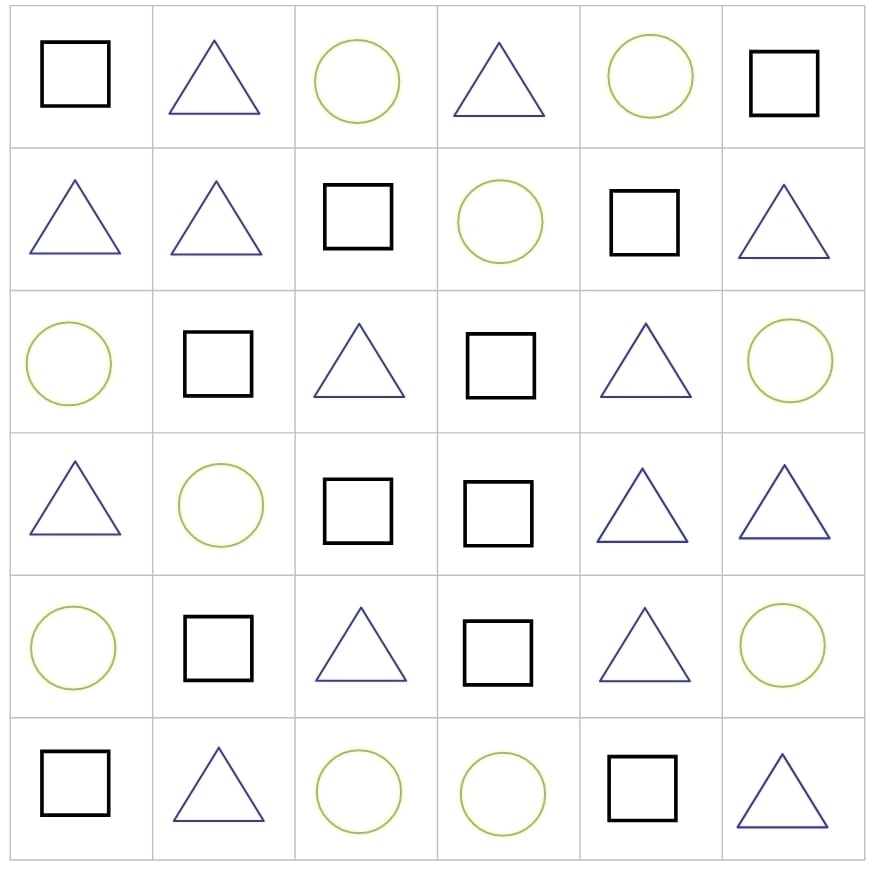


In [114]:
E = nx.DiGraph()

# Adicionando vértices
for letra in ['A', 'B', 'C', 'D', 'E', 'F']:
    for num in range(1, 7):
        E.add_nodes_from([f'{letra}{num}'])


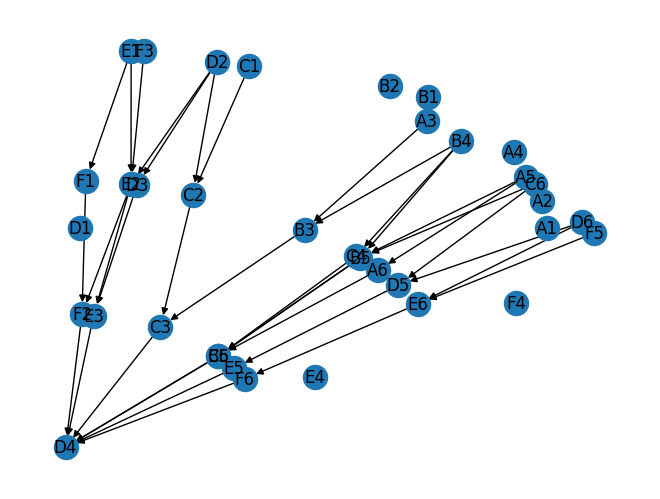

In [115]:
E.add_edges_from([
    ('C1', 'C2'),
    ('E1', 'E2'),
    ('E1', 'F1'),
    ('D2', 'C2'),
    ('D2', 'E2'),
    ('D2', 'D3'),
    ('A3', 'B3'),
    ('F3', 'E2'),
    ('B4', 'B3'),
    ('B4', 'C4'),
    ('B4', 'B5'),
    ('A5', 'B5'),
    ('A5', 'A6'),
    ('F5', 'E6'),
    ('C6', 'B5'),
    ('C6', 'D5'),
    ('D6', 'D5'),
    ('D6', 'E6'),
    ('F1', 'F2'),
    ('C2', 'C3'),
    ('E2', 'E3'),
    ('E2', 'F2'),
    ('B3', 'C3'),
    ('D3', 'E3'),
    ('C4', 'C5'),
    ('B5', 'B6'),
    ('B5', 'C5'),
    ('D5', 'E5'),
    ('A6', 'B6'),
    ('E6', 'F6'),
    ('F2', 'D4'),
    ('C3', 'D4'),
    ('E3', 'D4'),
    ('C5', 'D4'),
    ('E5', 'D4'),
    ('B6', 'D4'),
    ('F6', 'D4')
])

# Definindo o layout (i.e. posição dos vértices) a ser usado,
# posiciona os vértices aleatoriamente, raramente é uma boa opção...

layoutE = nx.kamada_kawai_layout(E)

nx.draw(E, pos=layoutE, with_labels=True)


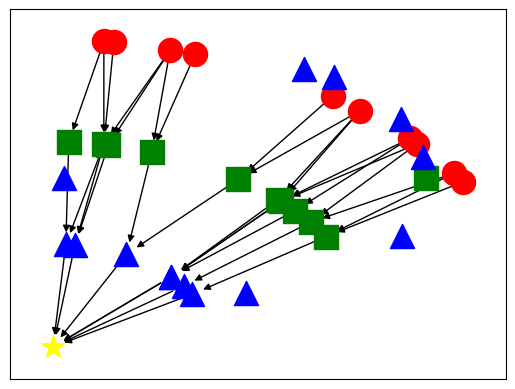

In [116]:
# O plot anterior é até interessante, mas podemos melhorá-lo
# Vamos usar formatos e cores diferentes para cada vértice, simulando as cores e formatos usados no exemplo visto em aula

circulos = ['A3', 'A5', 'B4', 'C1', 'C6', 'D2', 'D6', 'E1', 'F3', 'F5']
quadrados = ['A1', 'A6', 'B3', 'B5', 'C2', 'C4', 'D3', 'D5', 'E2', 'E6', 'F1']
final = ['D4']
triangulos = ['A2', 'A4', 'B1', 'B2', 'B6', 'C3',
              'C5', 'D1', 'E3', 'E4', 'E5', 'F2', 'F4', 'F6']

# Variando os formatos dos vértices
# Utilizaremos o comando nx.draw_networkx_nodes(G, pos, nodelist, node_shape, node_color)   disponível em https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_nodes.html#networkx.drawing.nx_pylab.draw_networkx_nodes
# Onde: 1) G é o grafo com as informações relevantes; 2) pos se refere ao posicionamento dos vértices; 3) nodelist é uma lista com os vétices a serem plotados; 4) node_shape é o formato a ser usado; 5) node_color é a cor do vértice
# Para o formato do vértice, podemos usar qualquer caracter a seguir (experimentem, na biblioteca do matplotlib podem ter opções adicionais): so^>v<dph8*
# Experimentem alterar as cores, é possivel usar um código em hexadecimal também, e.g. #0000FF é azul

nx.draw_networkx_nodes(E, pos=layoutE, nodelist=circulos,
                       node_shape='o', node_color='red')
nx.draw_networkx_nodes(E, pos=layoutE, nodelist=quadrados,
                       node_shape='s', node_color='green')
nx.draw_networkx_nodes(E, pos=layoutE, nodelist=triangulos,
                       node_shape='^', node_color='blue')
nx.draw_networkx_nodes(E, pos=layoutE, nodelist=final,
                       node_shape='*', node_color='yellow')

# imprimindo as arestas (ver documentação em https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_edges.html)
# o padrão imprimirá todos os vértices usando a cor preta

nx.draw_networkx_edges(E, pos=layoutE);

# Dica: usar o draw_network_edges() na última linha do bloco vai gerar um monte de saídas e textos indesejados. Para evitar isso adicionem um ponto-e-virgula no final do comando


Mesmo selecionado um bom layout, seria legal deixar os vértices dispostos da forma como vimos no exercício, traria uma intuição melhor e deixa claro qual vértice é qual


In [117]:
# Ao invés de usar uma das funções prontas para definir o layout, iremos passar as posições diretamente por meio de um dicionário
# o dicionário deve mapear vértices (chave) em coordenadas (valor)
# A rigor esse tipo de informação virá de uma outra estrutura (e.g. de um banco de dados), no nosso caso não temos isso, mas nomeamos os vértices em função da sua coordenada, vamos fazer esse processo novamente

posicoesNormais = dict()
coluna = 0
linha = 0
tamanhoMargem = 10  # Uma variável para controlar o espaço entre linhas e colunas

for letra in ['A', 'B', 'C', 'D', 'E', 'F']:
    coluna = coluna + 1
    for num in range(1, 7):
        posicoesNormais[letra+str(num)] = [coluna *
                                          tamanhoMargem, (6-linha)*tamanhoMargem]
        linha = linha+1
    linha = 0  # voltando a linha ao começo


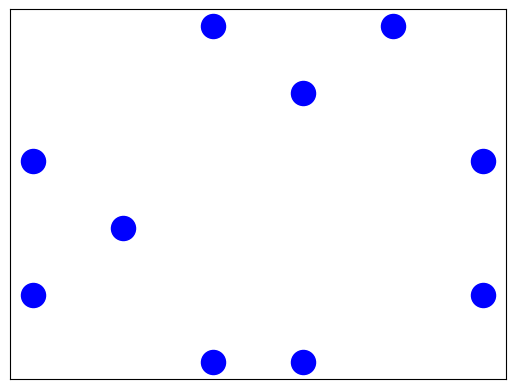

In [118]:
# Notem que podemos passar uma lista com todas as posições e o networkX irá usar apenas as necessárias; uma vez que passamos a lista de vértices (nodelist) desejada
# Desse modo, não precisamos criar uma variável com as posições dos círculos, depois dos quadrados, etc.

nx.draw_networkx_nodes(E, pos=posicoesNormais,
                       nodelist=circulos, node_shape='o', node_color='blue');


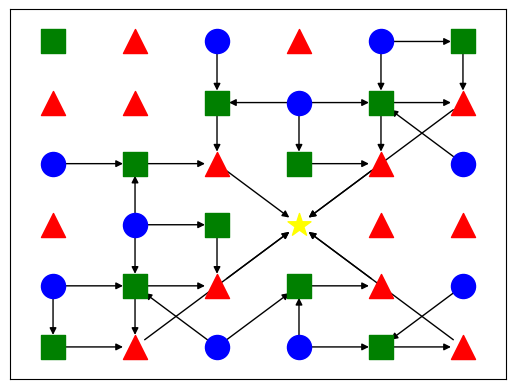

In [119]:
nx.draw_networkx_nodes(E, pos=posicoesNormais,
                       nodelist=circulos, node_shape='o', node_color='blue')
nx.draw_networkx_nodes(E, pos=posicoesNormais, nodelist=quadrados,
                       node_shape='s', node_color='green')
nx.draw_networkx_nodes(E, pos=posicoesNormais, nodelist=triangulos,
                       node_shape='^', node_color='red')
nx.draw_networkx_nodes(E, pos=posicoesNormais, nodelist=final,
                       node_shape='*', node_color='yellow')
nx.draw_networkx_edges(E, pos=posicoesNormais);


## Notem que algumas arestas se sobrepõem, no passo final de sair de um triângulo andando na diagonal e ir para o último ponto (estrela), dificultando o entendimento do grafo, que já está bem mais agradável. Mas pode melhorar.


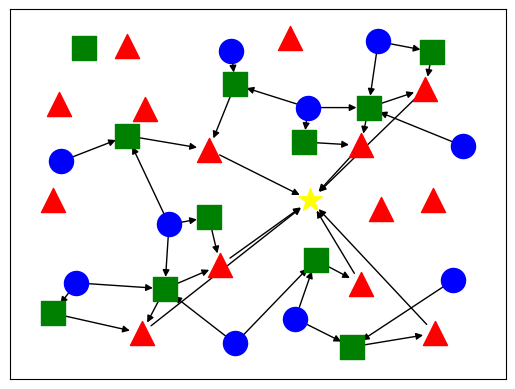

In [120]:
import random

posicoesRuidosas = dict()
for vertice in E.nodes:
    posicoesRuidosas[vertice] = [
        posicoesNormais[vertice][0] + random.uniform(-3, 3), posicoesNormais[vertice][1] + random.uniform(-3, 3)]

nx.draw_networkx_nodes(E, pos=posicoesRuidosas,
                       nodelist=circulos, node_shape='o', node_color='blue')
nx.draw_networkx_nodes(E, pos=posicoesRuidosas,
                       nodelist=quadrados, node_shape='s', node_color='green')
nx.draw_networkx_nodes(E, pos=posicoesRuidosas,
                       nodelist=triangulos, node_shape='^', node_color='red')
nx.draw_networkx_nodes(E, pos=posicoesRuidosas,
                       nodelist=final, node_shape='*', node_color='yellow')
nx.draw_networkx_edges(E, pos=posicoesRuidosas);
